# T1 - Aprendizado Não Supervisionado - Dataset Regenera

Aprendizado de Máquina - Prof. Me. Otávio Parraga - PUCRS

Grupo: Dhara Hadi, Júlia Bettiol, Gabriel Ottonelli, Matheus Azevedo, Samuel Morales e Thomaz Szeckir

Neste trabalho buscamos estrutura escondida na coleção de microrganismos marinhos do Banco Regenera, sem nenhum rótulo guiando o aprendizado. 

-Na Tarefa A, de agrupamento, escolhemos o K-Means e o agrupamento hierárquico aglomerativo com ligação de Ward. 

-Na Tarefa B, de redução de dimensionalidade, escolhemos a PCA como estratégia linear e o UMAP como estratégia não linear.

Organização:

0. Configuração
1. Pré-processamento (Exploração, limpeza e transformações)
2. Tarefa A - Agrupamento
3. Tarefa B - Redução de dimensionalidade
4. Análise crítica (Sensibilidade ao pré-processamento e conclusão)

## 0. Configuração

A célula abaixo importa as bibliotecas que usamos ao longo do trabalho e fixa a semente aleatória em 42, para que todos os resultados possam ser reproduzidos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency  # scipy: teste de independencia, hierarquico e comparacao de projecoes
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial import procrustes

from sklearn.preprocessing import StandardScaler, RobustScaler  # pre-processamento, agrupamento e reducao de dimensionalidade
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import trustworthiness

from sklearn.metrics import (  # metricas internas e externas de agrupamento
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_completeness_v_measure,
)

from sklearn.model_selection import StratifiedKFold, cross_val_score  # classificadores para medir a utilidade da reducao
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline

import umap  # reducao nao linear

SEED = 42  # semente e caminho do arquivo
np.random.seed(SEED)
DATA_PATH = "Data_REG.tsv"

pd.set_option("display.max_columns", 50)  # opcoes de exibicao
sns.set_theme(style="whitegrid")

## 1. Pré-processamento

Aqui fazemos a exploração do arquivo, a limpeza e as transformações antes de rodar qualquer modelo.

### 1.1 Exploração

#### Leitura e inventário

Lemos tudo como texto (`dtype=str`) para o pandas não transformar em NaN, sem avisar, os valores que ele não conseguisse converter. Assim a gente consegue ver a sujeira do arquivo.

In [2]:
df_raw = pd.read_csv(DATA_PATH, sep="\t", dtype=str)  # tudo como texto
print(df_raw.shape)
df_raw.head()

(506, 33)


,n°,GRAM,Cor,Cores,Borda,Textura,Forma,Brilho,Muco,Relevo,Atividade 01,Atividade 02,Atividade 03,Atividade 04,Atividade 05,Atividade 06,Atividade 07,Atividade 08,Atividade 09,Atividade 10,Atividade 11,Atividade 12,Atividade 13,Atividade 14,Atividade 15,Atividade 16,Atividade 17,Atividade 18,Atividade 19,Atividade 20,Atividade 21,Atividade 22,Atividade 23
0,1413,Negativo,1,2,0,1,1,2,0,1,0,0,Negativo,Negativo,1.2,0,0,-0.01,0.76,0.54,0.74,0.06,1,0,0,Positivo,1,1,3,1,3,0,2.767
1,1414,Positivo,1,2,0,1,4 & 1,2,0,0,0,2.33,Negativo,Negativo,1.2,-0.01,0.13,-0.04,0.28,0.1,0.09,0.04,0,2.8,3,Positivo,3,3,2,3,3,0,12.678
2,1415,Positivo,1,2,0,2 & 1,4 & 1,2,0,0,0,3.5,Negativo,Negativo,1.38,0,0.43,0.01,0.12,0.26,0.27,0.14,0,2,2.5,Positivo,3,3,3,3,3,3,6.87
3,1417,Negativo,1,2,0,1,1,2,0,1,0,0,Negativo,Negativo,1.25,0.67,0.11,0.03,0.99,0.67,0.24,0.11,2,0,0,Positivo,0,0,0,0,1,0,2.728
4,1418,Positivo,1,3,0,1,4 & 1,2,0,0,0,1.75,Negativo,Negativo,1.2,0,0.1,-0.02,0.24,0.26,0.09,0.17,0,2.33,1.2,Positivo,2,3,0,3,3,3,11.353


In [3]:
ID = "n°"
MORPH = ["Cor", "Cores", "Borda", "Textura", "Forma", "Brilho", "Muco", "Relevo"]
ACTS = [c for c in df_raw.columns if c.startswith("Atividade")]


def A(n):
    return f"Atividade {n:02d}"


BIN_ACTS = [A(n) for n in [1, 3, 4, 16]]
ORD_ACTS = [A(n) for n in [13, 17, 18, 19, 20, 21, 22]]
CONT_ACTS = [A(n) for n in [2, 5, 6, 7, 8, 9, 10, 11, 12, 14, 15, 23]]

assert sorted(BIN_ACTS + ORD_ACTS + CONT_ACTS) == sorted(ACTS)  # as tres listas cobrem as 23 atividades

In [4]:
tipo = {ID: "id", "GRAM": "referência"}
for c in MORPH:
    tipo[c] = "morfologia"
for c in BIN_ACTS:
    tipo[c] = "binária"
for c in ORD_ACTS:
    tipo[c] = "ordinal"
for c in CONT_ACTS:
    tipo[c] = "contínua"

inventario = pd.DataFrame(index=df_raw.columns)
inventario["tipo"] = pd.Series(tipo)
inventario["distintos"] = df_raw.nunique()
inventario["ausentes"] = df_raw.isna().sum()
inventario["exemplos"] = [list(df_raw[c].dropna().unique()[:6]) for c in df_raw.columns]
inventario

,tipo,distintos,ausentes,exemplos
n°,id,505,0,"[1413, 1414, 1415, 1417, 1418, 1419]"
GRAM,referência,7,0,"[Negativo, Positivo, Levedura, POSITIVO, Variá..."
Cor,morfologia,6,1,"[1, 2, 7, 3 & 5, 3, 6]"
Cores,morfologia,29,1,"[2, 3, 7, 5, 6, 5 & 3]"
Borda,morfologia,3,2,"[0, 2, 1]"
Textura,morfologia,4,2,"[1, 2 & 1, 2, 1 & 2]"
Forma,morfologia,7,3,"[1, 4 & 1, 4, 6, 4 & 2, 2]"
Brilho,morfologia,6,3,"[2, 1 & 2, 1, 4, 2 & 1, 0]"
Muco,morfologia,3,3,"[0, 1, 2]"
Relevo,morfologia,2,4,"[1, 0]"


São 506 linhas e 33 colunas, mas o `n°` só tem 505 valores distintos, então tem um isolado repetido.

Para classificar as atividades olhamos os valores de cada uma. Se só tem dois valores, é binária. Se só tem os inteiros de 0 a 3, é ordinal, porque parece um nível de intensidade. Se tem decimais e muitos valores, é contínua. Ficaram 4 binárias, 7 ordinais e 12 contínuas. Os ausentes das atividades estão na 20 (27), na 21 (17) e na 23 (3).

#### Valores das categóricas

In [5]:
for c in ["GRAM"] + MORPH:
    print(c, df_raw[c].value_counts(dropna=False).to_dict())

GRAM {'Negativo': 244, 'Positivo': 218, 'Levedura': 40, 'POSITIVO': 1, 'Variável': 1, 'Levedura? não ': 1, 'Positiva': 1}
Cor {'1': 432, '2': 68, '3': 2, nan: 1, '7': 1, '3 & 5': 1, '6': 1}
Cores {'3': 199, '2': 141, '6': 34, '4': 30, '5': 19, '2 & 1': 16, '2 & 3': 9, '3 & 4': 9, '1': 7, '3 & 1': 7, '6 & 2': 4, '4 & 2': 4, '6 & 1': 3, '3 & 6': 3, '0': 3, '3 & 2': 2, '5 & 2': 2, '7': 2, '2 & 5': 1, '1 & 6': 1, '7 & 1': 1, '6 & 4': 1, '4 & 5': 1, '7 & 2': 1, '20': 1, '1 & 2': 1, 'OBS': 1, nan: 1, '5 & 3': 1, '6;2': 1}
Borda {'0': 395, '2': 63, '1': 46, nan: 2}
Textura {'1': 327, '2': 154, '1 & 2': 16, '2 & 1': 7, nan: 2}
Forma {'1': 355, '4': 93, '4 & 1': 37, '4 & 2': 8, '2': 6, nan: 3, '6': 2, '1 & 2': 2}
Brilho {'2': 372, '1': 92, '1 & 2': 28, '2 & 1': 8, nan: 3, '0': 2, '4': 1}
Muco {'0': 369, '1': 133, nan: 3, '2': 1}
Relevo {'0': 307, '1': 195, nan: 4}


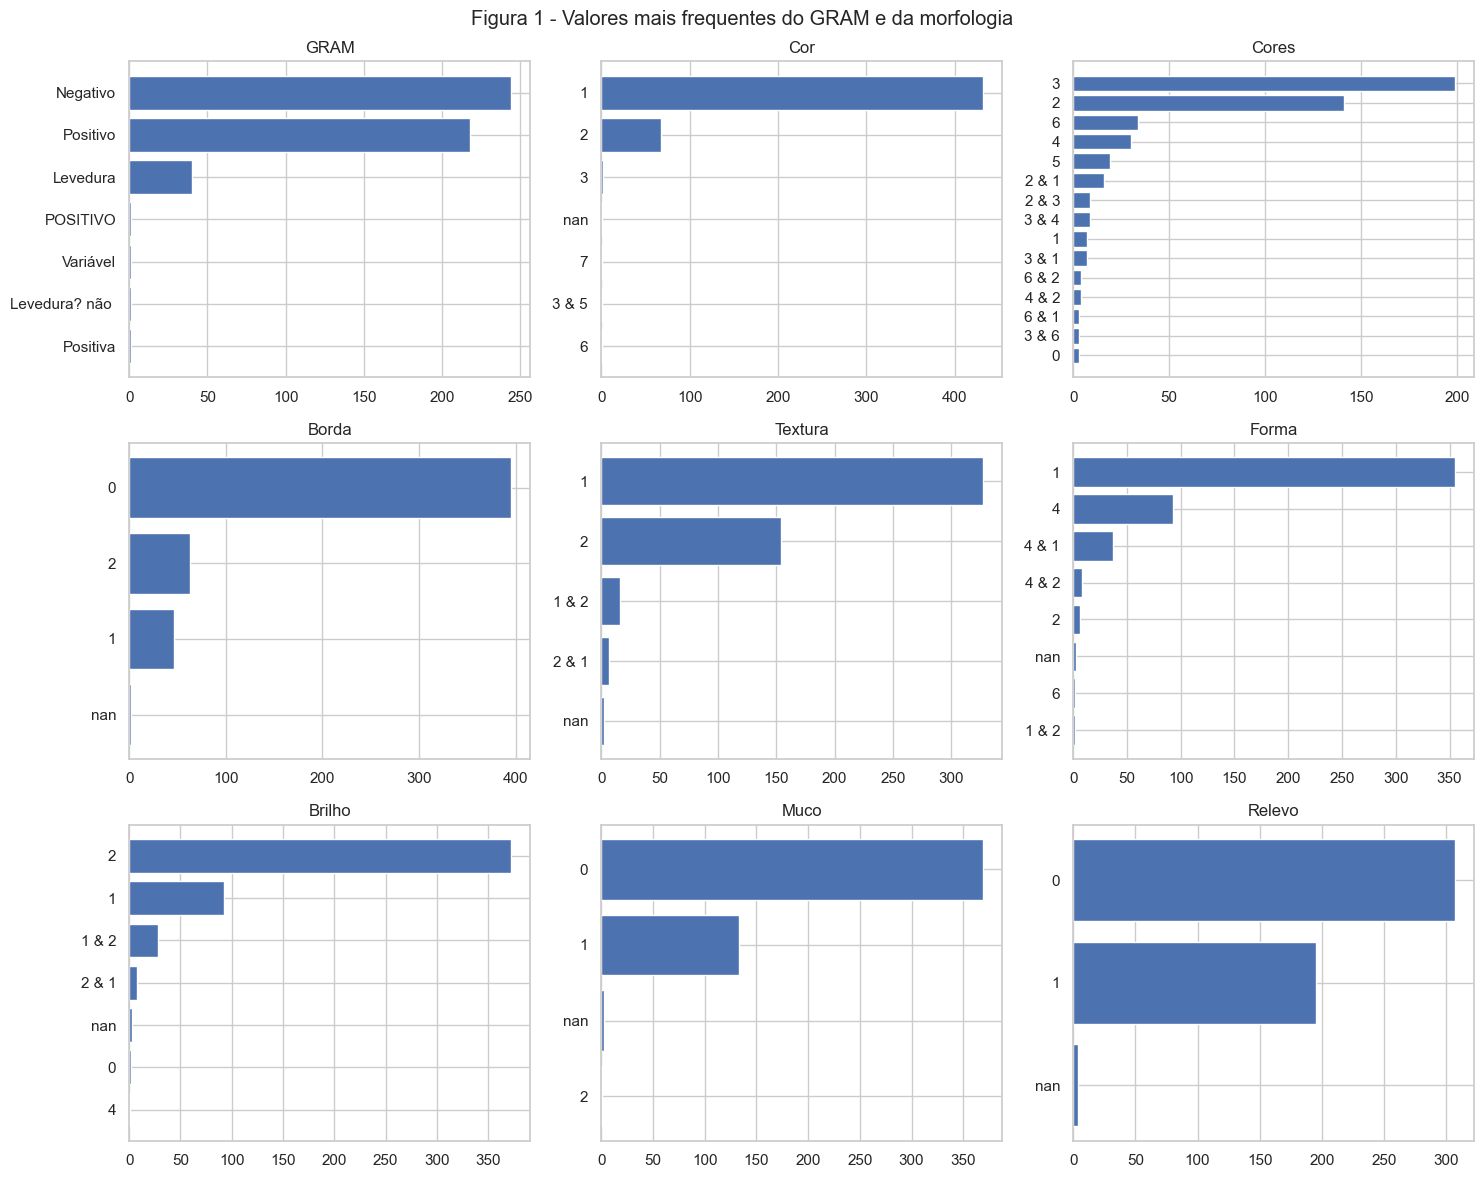

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, c in zip(axes.flat, ["GRAM"] + MORPH):
    vc = df_raw[c].value_counts(dropna=False).head(15)
    ax.barh([str(v) for v in vc.index], vc.values)  # str para o nan aparecer como rotulo
    ax.invert_yaxis()  # mais frequente em cima
    ax.set_title(c)
fig.suptitle("Figura 1 - Valores mais frequentes do GRAM e da morfologia")
plt.tight_layout()
plt.show()

Nas contagens e na Figura 1 já aparecem vários problemas. No GRAM tem "POSITIVO", "Positiva", "Variável" e "Levedura? não " (com espaço no final), cada um numa linha só. Na morfologia tem célula com dois códigos, às vezes em ordem trocada (em Brilho, "1 & 2" aparece 28 vezes e "2 & 1" aparece 8), e a coluna Cores tem um "OBS", um "6;2" e um "20". Também tem códigos que aparecem uma ou duas vezes, como o 7 em Cor e o 2 em Muco, e não dá para saber se são erro de digitação ou uma categoria rara.

Fora isso, em quase todas as colunas um ou dois valores dominam. Em Cor, por exemplo, o código 1 tem 432 dos 506 isolados.

#### Distribuições das atividades

Para fazer os gráficos, convertemos as atividades para número de forma provisória (Positivo = 1, Negativo = 0) e conferimos o que não era número.

In [7]:
acts_txt = df_raw[ACTS].replace({"Positivo": "1", "Negativo": "0"})
acts_num = acts_txt.apply(pd.to_numeric, errors="coerce")  # provisorio, so para explorar
acts_txt[acts_num.isna() & acts_txt.notna()].stack()  # valores que nao eram numero

275  Atividade 23    #NÚM!
dtype: object

In [8]:
tab = acts_num[CONT_ACTS].describe().T
tab["assimetria"] = acts_num[CONT_ACTS].skew()
tab["% zeros"] = (acts_num[CONT_ACTS] == 0).mean() * 100
tab["negativos"] = (acts_num[CONT_ACTS] < 0).sum()
tab.round(2)

,count,mean,std,min,25%,50%,75%,max,assimetria,% zeros,negativos
Atividade 02,506.0,0.95,1.25,0.00,0.00,0.00,1.98,5.83,0.96,58.50,0
Atividade 05,506.0,0.71,0.68,0.00,0.00,1.00,1.25,3.60,0.43,44.47,0
Atividade 06,506.0,0.09,0.19,-0.06,0.00,0.01,0.02,0.81,2.14,34.39,34
Atividade 07,506.0,0.12,0.13,-0.08,0.04,0.10,0.16,0.81,2.24,3.95,34
Atividade 08,506.0,0.02,0.04,-0.19,0.00,0.01,0.04,0.16,-0.05,14.23,125
Atividade 09,506.0,0.72,0.32,0.00,0.47,0.75,0.98,1.51,-0.23,0.59,0
Atividade 10,506.0,0.44,0.20,0.00,0.30,0.42,0.58,1.08,0.29,0.79,0
Atividade 11,506.0,0.27,0.14,0.00,0.17,0.24,0.36,0.74,0.77,0.20,0
Atividade 12,506.0,0.19,0.12,-0.08,0.11,0.18,0.26,0.70,0.96,0.20,1
Atividade 14,506.0,0.96,1.69,0.00,0.00,0.00,1.48,15.50,2.88,63.44,0


O único valor que não era número foi um "#NÚM!" na Atividade 23, que é erro de fórmula do Excel. Por enquanto ele virou NaN.

Na tabela dá para ver que as escalas são bem diferentes: a Atividade 23 vai até 577,89, e várias outras não passam de 1, então vamos precisar padronizar. Cinco colunas têm assimetria acima de 2 (06, 07, 14, 15 e 23), e algumas têm muito zero, como a 14, com 63,44%. Também tem negativos pequenos, principalmente na 08 (125), que parecem ruído de medida perto de zero.

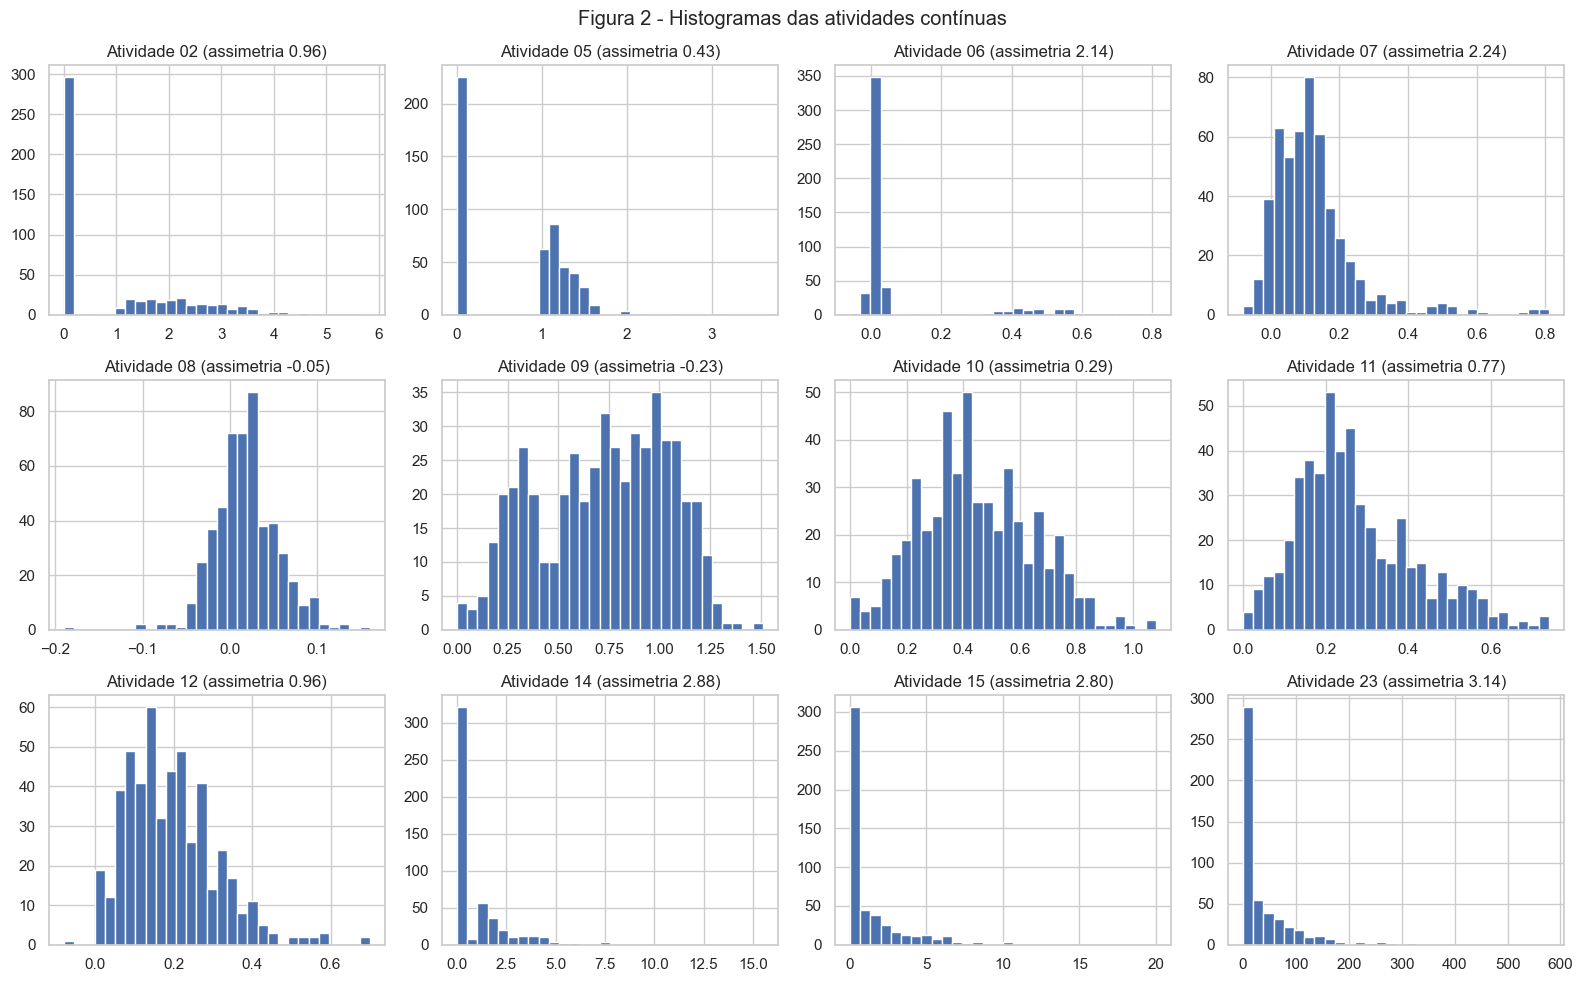

In [9]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, c in zip(axes.flat, CONT_ACTS):
    ax.hist(acts_num[c].dropna(), bins=30)
    ax.set_title(f"{c} (assimetria {acts_num[c].skew():.2f})")
fig.suptitle("Figura 2 - Histogramas das atividades contínuas")
plt.tight_layout()
plt.show()

Na Figura 2, as Atividades 02, 14, 15 e 23 têm um pico grande perto do zero e uma cauda longa para a direita. A 05 e a 06 são curiosas: têm o pico no zero e depois um segundo grupo separado, como se o isolado ou não respondesse ou respondesse com uma intensidade típica. Já a 08, a 09 e a 10 são mais simétricas.

Pelo que vimos, as candidatas ao log são as cinco com assimetria acima de 2 (06, 07, 14, 15 e 23).

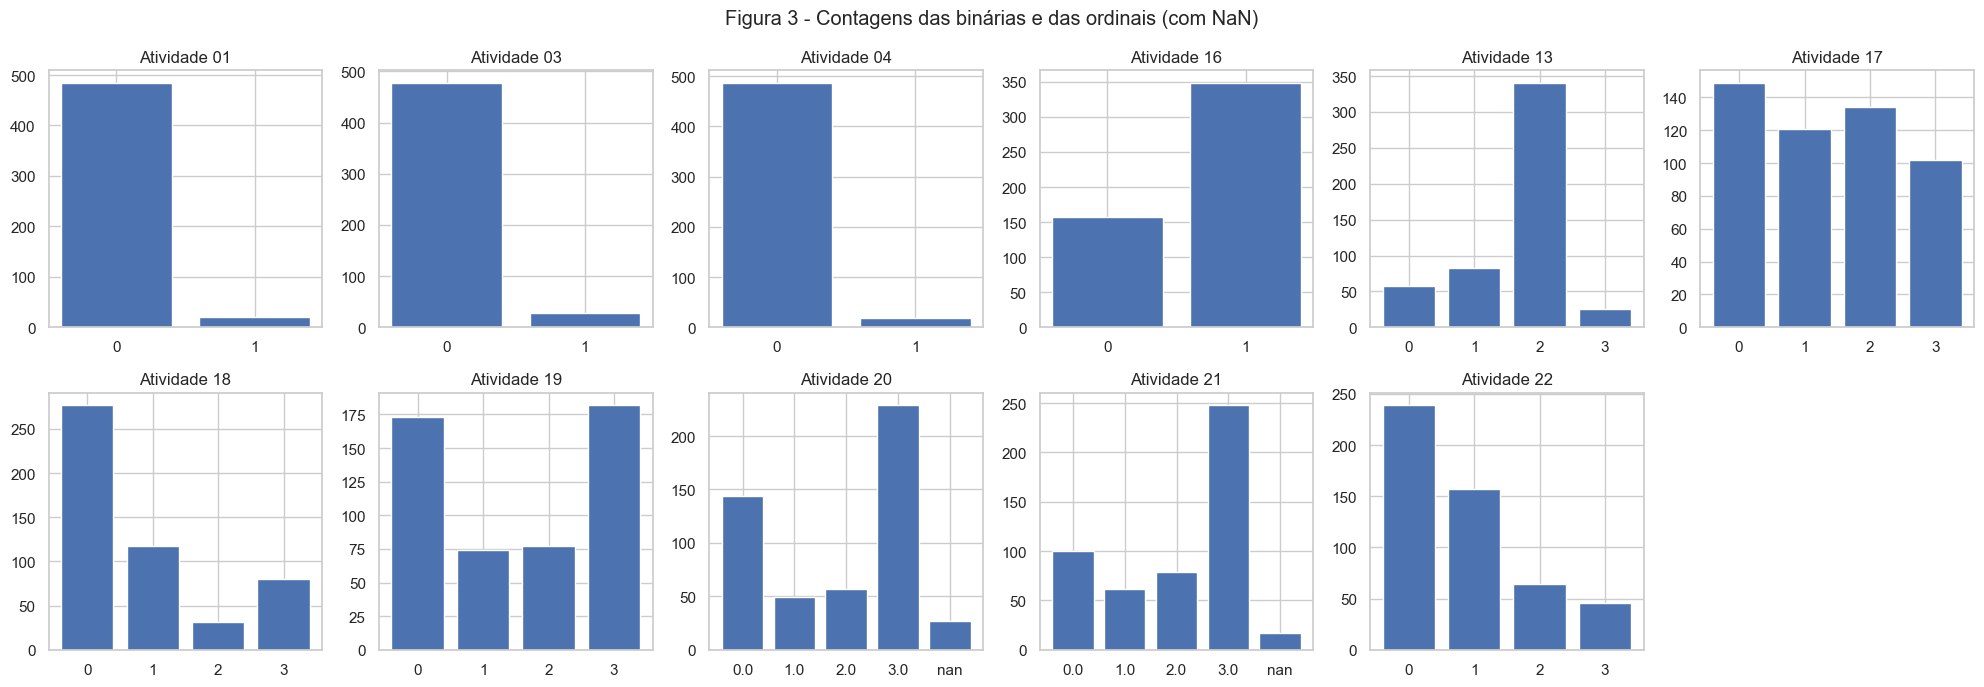

In [10]:
fig, axes = plt.subplots(2, 6, figsize=(20, 7))
for ax, c in zip(axes.flat, BIN_ACTS + ORD_ACTS):
    vc = acts_num[c].value_counts(dropna=False).sort_index()
    ax.bar([str(v) for v in vc.index], vc.values)
    ax.set_title(c)
axes.flat[-1].axis("off")  # sobra um quadro
fig.suptitle("Figura 3 - Contagens das binárias e das ordinais (com NaN)")
plt.tight_layout()
plt.show()

Na Figura 3, três binárias quase nunca dão positivo: a 01 tem 21 positivos, a 03 tem 28 e a 04 tem 19. Isso preocupa porque, se padronizarmos, esses poucos positivos viram valores bem altos e pesam muito. A 16 é o contrário, com 349 positivos.

Nas ordinais cada atividade tem um formato: a 13 concentra quase tudo no nível 2, a 19 tem forma de U e a 17 é bem equilibrada. Os únicos ausentes estão na 20 e na 21.

#### Relações entre as atividades

Usamos Spearman em vez de Pearson porque temos binárias, ordinais e contínuas com cauda longa na mesma matriz. O Spearman usa a ordem dos valores, então não precisa de relação linear e não se deixa levar pelos valores extremos.

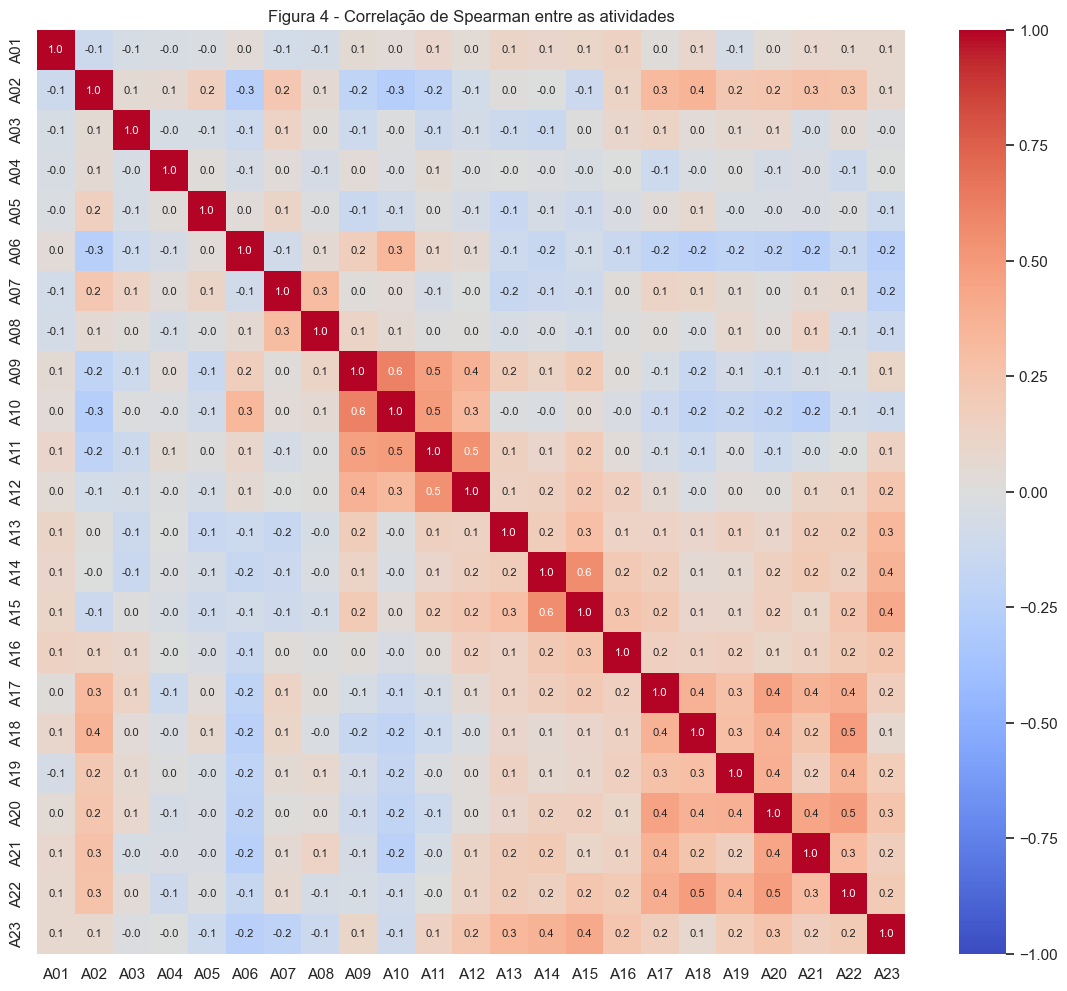

Atividade 09  Atividade 10    0.610
Atividade 14  Atividade 15    0.562
Atividade 11  Atividade 12    0.541
Atividade 10  Atividade 11    0.487
Atividade 18  Atividade 22    0.482
Atividade 20  Atividade 22    0.476
Atividade 09  Atividade 11    0.464
Atividade 17  Atividade 20    0.446
Atividade 20  Atividade 21    0.439
Atividade 15  Atividade 23    0.417
Atividade 17  Atividade 22    0.395
Atividade 19  Atividade 20    0.382
dtype: float64

In [11]:
corr = acts_num.corr(method="spearman")
curtos = ["A" + c[-2:] for c in ACTS]

plt.figure(figsize=(14, 12))
sns.heatmap(corr, annot=True, fmt=".1f", cmap="coolwarm", vmin=-1, vmax=1,
            xticklabels=curtos, yticklabels=curtos, annot_kws={"size": 8})
plt.title("Figura 4 - Correlação de Spearman entre as atividades")
plt.show()

pares = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()  # cada par so uma vez
pares.reindex(pares.abs().sort_values(ascending=False).index).head(12).round(3)

Na Figura 4 a maior parte da matriz fica perto de zero, e nenhum par passa de 0,7, então nenhuma atividade é cópia de outra. As Atividades 01, 03, 04 e 05 quase não se relacionam com nenhuma outra.

Os pares mais correlacionados formam três blocos: as Atividades 09, 10, 11 e 12 (o par mais forte é 09 e 10, com 0,61), as ordinais de 17 a 22, que aparecem em seis dos doze pares, e as de cauda longa 14, 15 e 23 (14 e 15 com 0,562). Isso indica que as 23 atividades têm bem menos de 23 "direções" independentes, o que deve ajudar a PCA. Como os ensaios são anonimizados, não dá para saber o que cada bloco mede.

### 1.2 Limpeza

Todas as correções vão para um log, com o problema, a coluna, os valores, quantas linhas e o que fizemos. Trabalhamos numa cópia, para não mexer no arquivo cru.

In [12]:
log = []


def registra(problema, coluna, valores, n, tratamento):
    log.append({"problema": problema, "coluna": coluna, "valores": valores, "n": n, "tratamento": tratamento})


df = df_raw.copy()

for c in df.columns:  # a) espacos sobrando
    sujos = df[c].notna() & (df[c] != df[c].str.strip())
    if sujos.any():
        registra("espaço sobrando", c, list(df.loc[sujos, c].unique()), sujos.sum(), "strip()")
        df[c] = df[c].str.strip()

errados = df["GRAM"].isin(["POSITIVO", "Positiva"])  # b) gram
registra("grafia diferente", "GRAM", list(df.loc[errados, "GRAM"].unique()), errados.sum(), "virou Positivo")
df.loc[errados, "GRAM"] = "Positivo"
fora = ~df["GRAM"].isin(["Positivo", "Negativo", "Levedura"])
registra("categoria fora do esperado", "GRAM", list(df.loc[fora, "GRAM"].unique()), fora.sum(), "NaN (linha mantida, só fica fora das métricas externas)")
df.loc[fora, "GRAM"] = np.nan

rep = df[ID] == "1551"  # c) id repetido: mesma morfologia, atividades diferentes
df.loc[rep, ID] = ["1551_a", "1551_b"]
registra("ID repetido", ID, ["1551"], rep.sum(), "mantidas como 1551_a e 1551_b (a 4.1 testa remover)")

for c in ACTS:  # d) residuo de formula do excel
    formula = df[c].str.startswith("#", na=False)
    if formula.any():
        registra("resíduo de fórmula", c, list(df.loc[formula, c].unique()), formula.sum(), "NaN")
        df.loc[formula, c] = np.nan

for c in BIN_ACTS:  # e) binarias escritas por extenso
    if df[c].isin(["Positivo", "Negativo"]).any():
        registra("binária escrita por extenso", c, ["Positivo", "Negativo"], len(df), "Positivo = 1, Negativo = 0")
        df[c] = df[c].replace({"Positivo": "1", "Negativo": "0"})

df[ACTS] = df[ACTS].apply(pd.to_numeric)  # sem coerce: se sobrasse texto daria erro

In [13]:
DOMINIO = {"Cor": (1, 7), "Cores": (0, 7), "Borda": (0, 2), "Textura": (1, 2),  # f) morfologia: menor e maior codigo valido
           "Forma": (1, 6), "Brilho": (1, 2), "Muco": (0, 1), "Relevo": (0, 1)}


def le_codigos(valor, col):
    if pd.isna(valor):
        return np.nan, None
    partes = [p.strip() for p in valor.replace(";", "&").split("&")]
    if not all(p.isdigit() for p in partes):
        return np.nan, "texto não numérico"
    codigos = tuple(sorted(set(int(p) for p in partes)))  # ordenado: 2 & 1 e 1 & 2 viram (1, 2)
    menor, maior = DOMINIO[col]
    if any(c < menor or c > maior for c in codigos):
        return np.nan, "código fora do domínio"
    return codigos, None


for col in MORPH:
    pv = df[col].str.contains(";", na=False)
    if pv.any():
        registra("separador ;", col, list(df.loc[pv, col].unique()), pv.sum(), "trocado por &")

    novos, ruins = [], {}
    for v in df[col]:
        cod, motivo = le_codigos(v, col)
        novos.append(cod)
        if motivo:
            ruins.setdefault(motivo, []).append(v)
    for motivo, vals in ruins.items():
        registra(motivo, col, sorted(set(vals)), len(vals), "NaN")
    df[col] = pd.Series(novos, index=df.index, dtype=object)

    multi = df[col].apply(lambda t: isinstance(t, tuple) and len(t) > 1)
    if multi.any():
        registra("mais de um código", col, list(df_raw.loc[multi, col].unique()), multi.sum(), "tupla ordenada")

In [14]:
for col in MORPH:  # g) ausentes da morfologia: moda
    n = df[col].isna().sum()
    if n > 0:
        moda = df[col].dropna().value_counts().index[0]
        registra("ausente", col, [], n, "moda " + "&".join(str(c) for c in moda))
        df[col] = df[col].apply(lambda t: t if isinstance(t, tuple) else moda)

for c in ACTS:  # continuas: mediana; binarias e ordinais: moda
    n = df[c].isna().sum()
    if n > 0:
        if c in CONT_ACTS:
            valor, nome = df[c].median(), "mediana"
        else:
            valor, nome = df[c].mode()[0], "moda"
        registra("ausente", c, [], n, f"{nome} {valor:g}")
        df[c] = df[c].fillna(valor)

for c in CONT_ACTS:  # h) negativos: so registra, ficam como estao
    neg = df[c] < 0
    if neg.any():
        registra("valor negativo", c, [df[c].min()], neg.sum(), "mantido (ruído perto de zero, o log1p aceita > -1)")

log_df = pd.DataFrame(log)
log_df

,problema,coluna,valores,n,tratamento
0,espaço sobrando,GRAM,[Levedura? não ],1,strip()
1,grafia diferente,GRAM,"[POSITIVO, Positiva]",2,virou Positivo
2,categoria fora do esperado,GRAM,"[Variável, Levedura? não]",2,"NaN (linha mantida, só fica fora das métricas ..."
3,ID repetido,n°,[1551],2,mantidas como 1551_a e 1551_b (a 4.1 testa rem...
4,resíduo de fórmula,Atividade 23,[#NÚM!],1,NaN
5,binária escrita por extenso,Atividade 03,"[Positivo, Negativo]",506,"Positivo = 1, Negativo = 0"
6,binária escrita por extenso,Atividade 04,"[Positivo, Negativo]",506,"Positivo = 1, Negativo = 0"
7,binária escrita por extenso,Atividade 16,"[Positivo, Negativo]",506,"Positivo = 1, Negativo = 0"
8,mais de um código,Cor,[3 & 5],1,tupla ordenada
9,separador ;,Cores,[6;2],1,trocado por &


In [15]:
df_clean = df.copy()
print(df_clean.shape)
print("ausentes que sobraram:", df_clean.isna().sum().sum())
print(df_clean["GRAM"].value_counts(dropna=False))

(506, 33)
ausentes que sobraram: 2
GRAM
Negativo    244
Positivo    220
Levedura     40
NaN           2
Name: count, dtype: int64


O log ficou com 33 registros. Resumindo o que decidimos: as grafias do GRAM foram corrigidas, e "Variável" e "Levedura? não" viraram NaN sem tirar as linhas, já que o GRAM não entra no agrupamento. As duas linhas do 1551 ficaram, como 1551_a e 1551_b. O "#NÚM!" virou NaN, as binárias viraram 0/1 e, na morfologia, "2 & 1" e "1 & 2" passaram a ser a mesma coisa. Os ausentes foram preenchidos com a moda (morfologia, binárias e ordinais) ou com a mediana (contínuas), e os negativos ficaram. No fim, só sobraram os 2 NaN do GRAM.

Uma ressalva: os códigos fora do domínio, como o 20 em Cores e o 0 e o 4 em Brilho, viraram NaN e depois a moda. Mas não temos como saber se eram erro de digitação ou uma categoria real e rara. Escolhemos tratar como erro e fizemos igual em todas as colunas.

#### Relações depois da limpeza

Com os dados limpos, vemos se a morfologia tem a ver com o GRAM, usando o V de Cramér (vai de 0 a 1), e como as atividades mudam de um GRAM para outro. Usamos só as linhas com GRAM preenchido.

Cor        0.063
Cores      0.327
Borda      0.091
Textura    0.111
Forma      0.126
Brilho     0.307
Muco       0.117
Relevo     0.106
dtype: float64


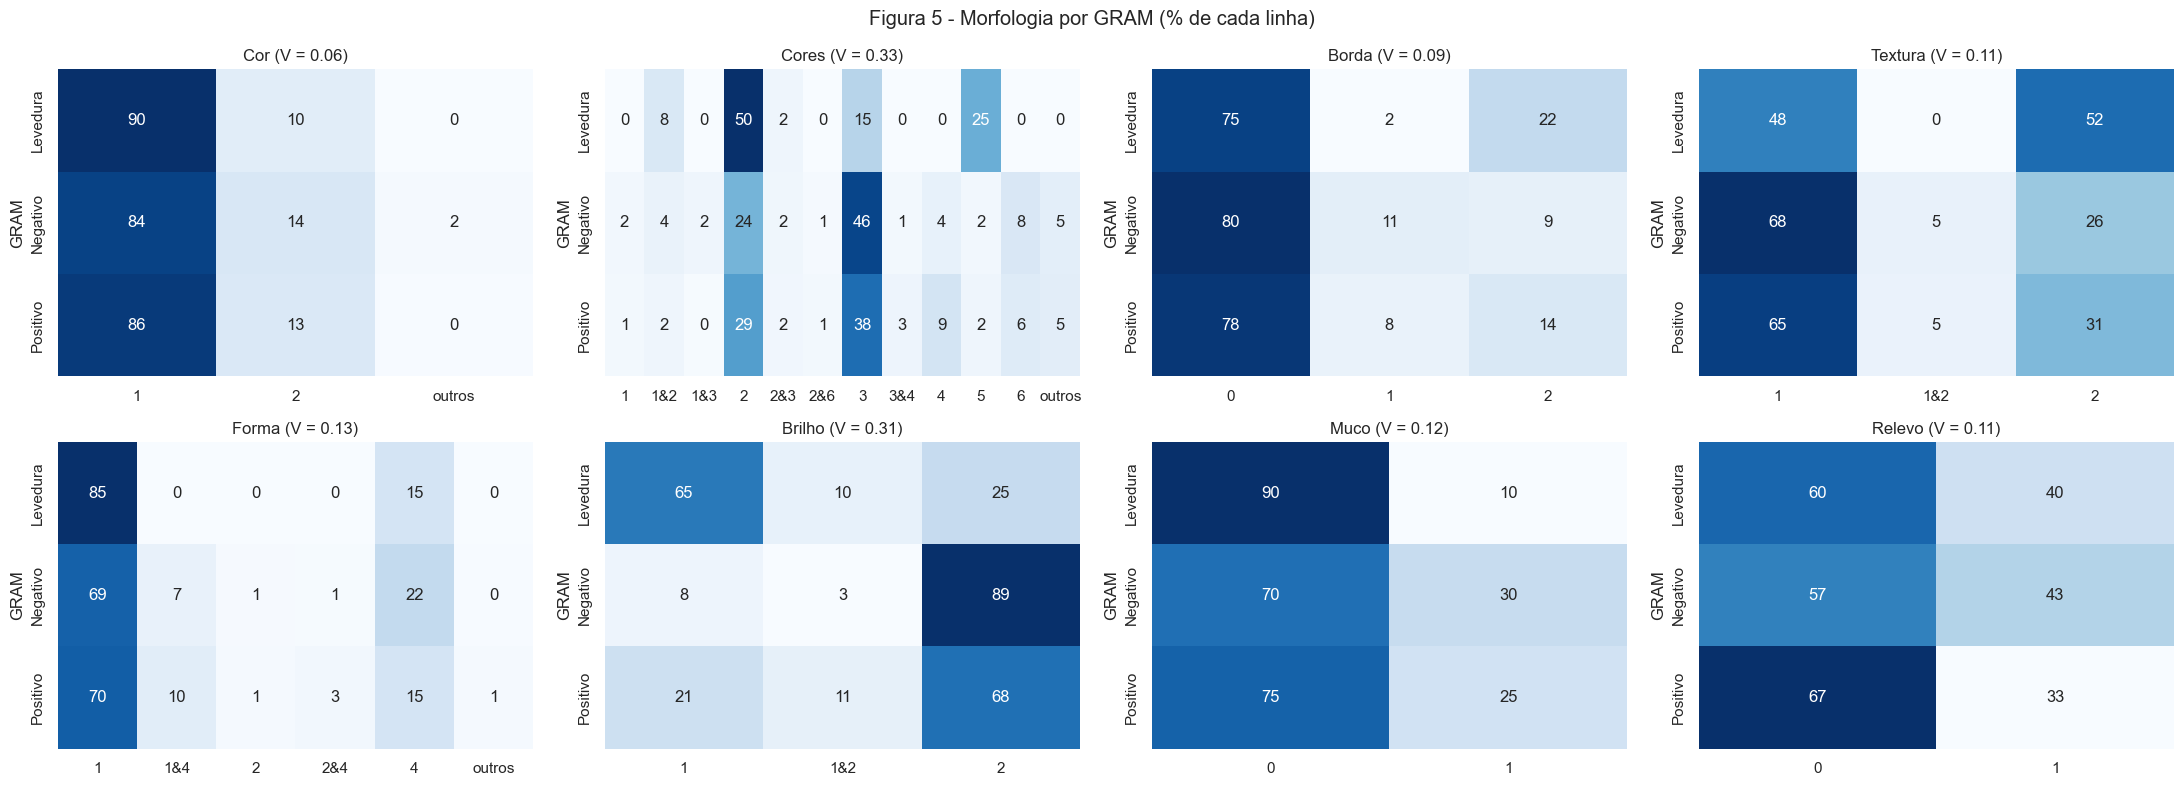

In [16]:
morph_str = df_clean[MORPH].apply(lambda col: col.map(lambda t: "&".join(str(c) for c in t)))  # tupla vira texto


def cramers_v(x, y):
    tab = pd.crosstab(x, y)
    chi2 = chi2_contingency(tab)[0]
    return np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))


tem_gram = df_clean["GRAM"].notna()
gram = df_clean.loc[tem_gram, "GRAM"]
v = pd.Series({c: cramers_v(gram, morph_str.loc[tem_gram, c]) for c in MORPH})
print(v.round(3))

fig, axes = plt.subplots(2, 4, figsize=(22, 8))
for ax, c in zip(axes.flat, MORPH):
    s = morph_str.loc[tem_gram, c]
    s = s.where(s.map(s.value_counts()) >= 5, "outros")  # codigos com menos de 5 isolados, so na figura
    tab = pd.crosstab(gram, s, normalize="index") * 100
    sns.heatmap(tab, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{c} (V = {v[c]:.2f})")
    ax.set_xlabel("")
fig.suptitle("Figura 5 - Morfologia por GRAM (% de cada linha)")
plt.tight_layout()
plt.show()

Pelo V de Cramér, a morfologia tem pouca relação com o GRAM. Os maiores são Cores (0,327) e Brilho (0,307), e o resto fica abaixo de 0,13. Na Figura 5 dá para ver de onde vem isso: em Brilho, 89% dos Negativos têm código 2, enquanto 65% das Leveduras têm código 1, e em Cores metade das Leveduras tem a cor 2. Só que as Leveduras são só 40 isolados, então essas porcentagens mudam bastante com poucos casos.

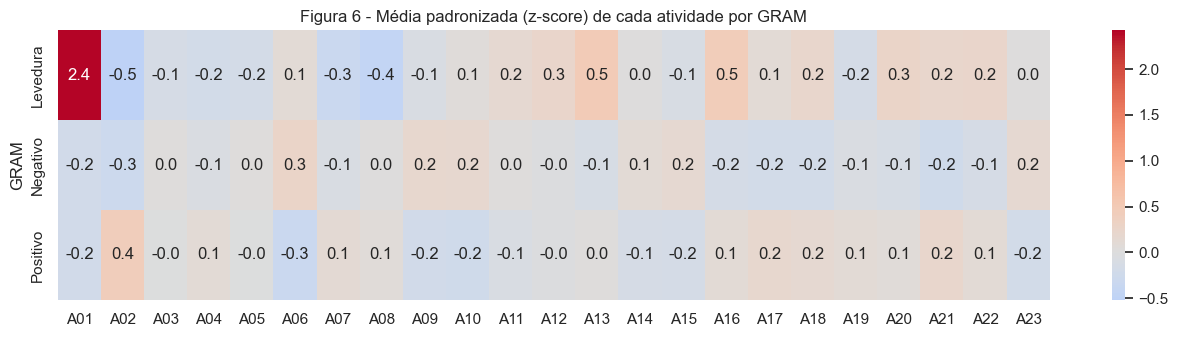

In [17]:
z = (df_clean[ACTS] - df_clean[ACTS].mean()) / df_clean[ACTS].std()  # z-score de cada atividade
media_gram = z[tem_gram].groupby(gram).mean()

plt.figure(figsize=(16, 3.5))
sns.heatmap(media_gram, annot=True, fmt=".1f", cmap="coolwarm", center=0, xticklabels=curtos)
plt.title("Figura 6 - Média padronizada (z-score) de cada atividade por GRAM")
plt.show()

Na Figura 6 a maioria das médias fica entre -0,3 e 0,3, ou seja, as atividades mudam pouco de um GRAM para outro. O destaque é a Atividade 01 nas Leveduras, com média 2,4 desvios acima da geral, o que sugere que essa atividade rara aparece mais nelas. As Leveduras também ficam um pouco acima na 13 e na 16 (0,5). Isso reforça que o GRAM não deve explicar muito dos grupos que vamos encontrar.

### 1.3 Transformações

Para o agrupamento e a redução usamos só as 23 atividades. A morfologia fica para caracterizar os grupos depois, o GRAM é só referência externa e o `n°` sai.

| Decisão | Escolha | Por quê |
|---|---|---|
| Cauda longa | `log1p` nas Atividades 06, 07, 14, 15 e 23 | têm assimetria acima de 2, e o `log1p` aceita o zero e os negativos pequenos |
| Escala | StandardScaler em tudo | K-Means, Ward e PCA usam distância e variância, e sem isso a 23 dominaria |
| Binárias | 0/1 e depois padronizadas | ficam na mesma escala das outras |
| Ordinais | números de 0 a 3 | a ordem dos níveis tem sentido |
| Morfologia | multi-hot (uma coluna 0/1 por código) | uma célula pode ter mais de um código e os códigos não são quantidades |

Uma coisa importante: padronizar binárias raras, como a 04, que tem só 19 positivos, faz cada positivo pesar bastante. Fizemos isso de propósito, porque para bioprospecção um isolado com uma atividade rara é justamente o que interessa. Na seção 4.1 testamos deixar as binárias sem padronizar.

In [18]:
LOG_COLS = [A(n) for n in [6, 7, 14, 15, 23]]


def preprocess(df_in, use_log=True, scaler="standard"):
    X = df_in[ACTS].astype(float)
    if use_log:
        X[LOG_COLS] = np.log1p(X[LOG_COLS])
    if scaler == "standard":
        sc = StandardScaler()
    else:
        sc = RobustScaler()
    Xs = pd.DataFrame(sc.fit_transform(X), columns=ACTS, index=X.index)
    return X, Xs  # sem escala e escalado


X_tr, Xs = preprocess(df_clean)
X = Xs.values


def multi_hot(df_in):
    M = pd.DataFrame(index=df_in.index)
    for col in MORPH:
        codigos = sorted(set(c for t in df_in[col] for c in t))
        for cod in codigos:
            M[f"{col}_{cod}"] = df_in[col].apply(lambda t: int(cod in t))  # 1 se o codigo aparece na celula
    return M


M = multi_hot(df_clean)
print(X.shape, M.shape)

(506, 23) (506, 29)


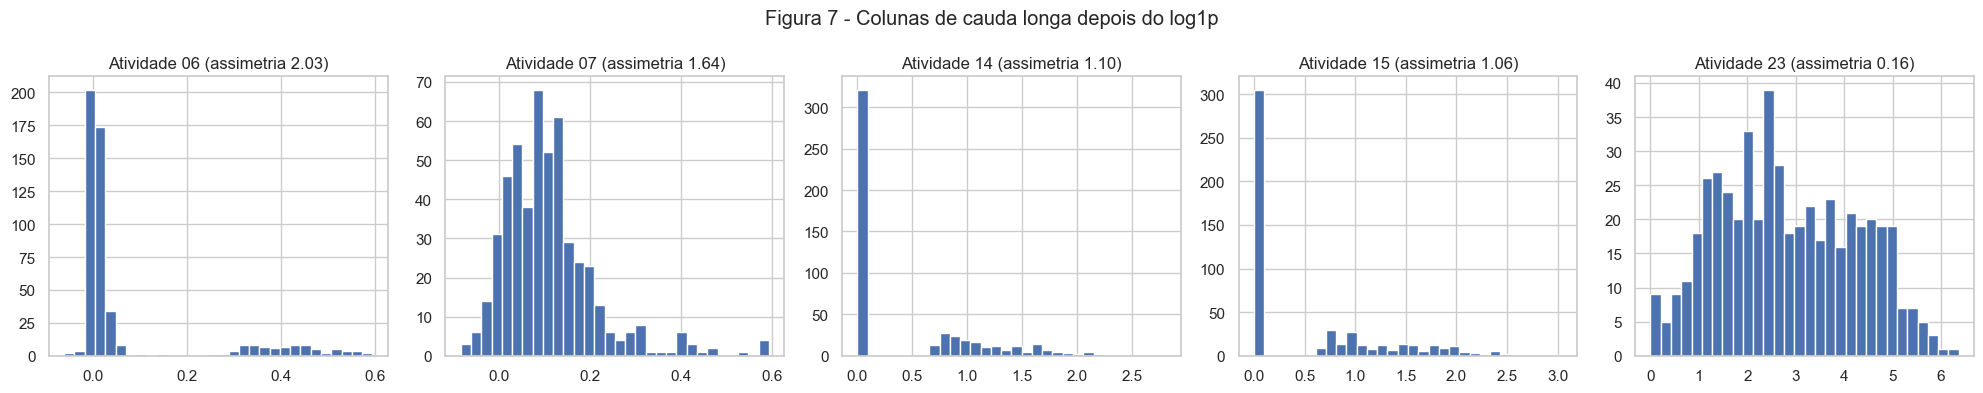

In [19]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, c in zip(axes, LOG_COLS):
    ax.hist(X_tr[c], bins=30)
    ax.set_title(f"{c} (assimetria {X_tr[c].skew():.2f})")
fig.suptitle("Figura 7 - Colunas de cauda longa depois do log1p")
plt.tight_layout()
plt.show()

Comparando a Figura 7 com a Figura 2, o log funcionou bem em algumas colunas e quase nada em outras. A 06 quase não mudou (de 2,14 para 2,03): os valores dela vão só até 0,81, e para números menores que 1 o `log1p` é quase uma reta, então a forma continua igual. Ela também continua bimodal, com um pico perto de zero e um grupo separado entre 0,3 e 0,6. A 07 mudou um pouco (de 2,24 para 1,64), pelo mesmo motivo.

A 14 e a 15 caíram para 1,10 e 1,06, mas o pico no zero continua, porque o log de zero é zero e mais de 60% dos isolados têm zero nelas. A 23 foi a que mais melhorou, de 3,14 para 0,16, e ficou quase simétrica.